# 01c — The OSM rail network: source, cleaning, snapping, distance to Košice

Builds the network on which every **rail distance** of the study is measured, and documents each choice
(Reviewer 1: extraction date, type rules, disconnected components, directionality, cross-border topology,
snap-distance distribution, validation). Reads the station catalog written by **01b**
(`output/kosice/station_tags.csv`). Code: `traintranv2/nb01c_rail_network.py`.

| § | step | output |
|---|---|---|
| 1 | source: what the gpkg is, its extraction date | `data/osm/v4_railways.manifest.json` |
| 2 | type rules: `rail` + `narrow_gauge` + the TEŽ (`light_rail`: ref 112D, or 1000 mm inside SK) | `rail_network_cleaning.csv` |
| 3 | duplicates (overlapping country dumps), clip to the six countries | `rail_network_ways.csv` |
| 4 | graph, components, gap joins | `rail_network_components.csv`, `rail_network_added_edges.csv` |
| 5 | stations: snap (≤ 2 km, else discarded), links across gauge breaks | `station_rail_snap.csv` |
| 5b | bridges: cut-off pieces with stations joined over `construction` track (that path only) | `rail_network_bridges.csv` |
| 6 | distance from the Košice station; detour check | `station_rail_snap.csv` |
| 7 | the 31 stations the legacy run could not reach | — |

The legacy network (`traintran/rail_network.py`, `ksc_explore_domestic.ipynb`) and `output/ke/` are untouched.

In [1]:
import os, sys

# Run from the project root so every relative path ('data/...', 'traintranv2/...') resolves the
# same whether the notebook is launched from notebooks/ or from the root.
_here = os.path.abspath('')
if os.path.basename(_here) == 'notebooks':
    os.chdir(os.path.dirname(_here))
sys.path.insert(0, os.getcwd())
print('Working directory:', os.getcwd())

Working directory: E:\notes\api_zssk\project


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import traintranv2  # noqa: F401  (PROJ data fix)
from traintranv2.config import default_config
from traintranv2 import nb01c_rail_network as R
from traintranv2.nb01a_feeds import write_meta

cfg = default_config()
OUT = cfg.out_dir
os.makedirs(OUT, exist_ok=True)
cleaning = []          # one row per step -> rail_network_cleaning.csv
print(f'network types : {cfg.rail_types} + light_rail with ref {cfg.rail_extra_refs} (TEŽ)')
print(f'study area    : {cfg.study_countries} NUTS0 + {cfg.rail_clip_buffer_km:g} km; metric CRS {cfg.rail_metric_crs}')
print(f'cleaning      : node grid {cfg.rail_node_grid_m} m, gap join <= {cfg.rail_gap_join_m:g} m, '
      f'station link <= {cfg.rail_station_link_m:g} m, snap discard > {cfg.rail_snap_max_km:g} km')
print(f'hub           : {cfg.domestic_feed}:{cfg.hub_stop_id} ({cfg.hub_label} station)')

network types : ['rail', 'narrow_gauge'] + light_rail with ref ['112D'] (TEŽ)
study area    : ['CZ', 'SK', 'AT', 'HU', 'PL', 'UA'] NUTS0 + 5 km; metric CRS EPSG:3035
cleaning      : node grid 0.5 m, gap join <= 25 m, station link <= 300 m, snap discard > 2 km
hub           : ZSR_SK:5613600 (Košice station)


## 1. Source and extraction date

`data/osm/v4_railways.gpkg` is one layer (`railways`, the OSM *lines* of `ogr2ogr`) assembled from **several
OSM country dumps**. Its **extraction date** is the time the layer was written, `gpkg_contents.last_change`;
the dumps' own dates are not stored in the file. The file's modification time is *not* used (a desktop GIS
opening the file changes it). The manifest pins the file by size and sha256.

In [3]:
man = R.osm_manifest(cfg)
print(f"extraction date : {man['extraction_date']}  ({man['extraction_date_source']})")
print(f"file            : {man['file']}  {man['bytes'] / 1e6:.1f} MB  sha256 {man['sha256'][:16]}…")
print(f"extent (WGS84)  : {man['extent_wgs84']}")
print(f"rows            : {man['rows']:,}  distinct osm_id {man['distinct_osm_id']:,}  -> "
      f"{man['duplicate_rows']:,} duplicate rows (overlapping country dumps)")
print(f"[wrote] {R.manifest_path(cfg)}")
display(pd.Series(man['rows_by_railway'], name='rows').to_frame().head(20))

extraction date : 2026-05-28T08:42:21.097Z  (gpkg_contents.last_change: when the layer was written from the OSM country dumps (the dumps' own dates are not recorded in the file))
file            : data/osm/v4_railways.gpkg  233.7 MB  sha256 965df123e363e68c…
extent (WGS84)  : [9.55887222290039, 44.5129165649414, 40.25245285034179, 55.42524719238281]
rows            : 440,511  distinct osm_id 423,638  -> 16,873 duplicate rows (overlapping country dumps)
[wrote] data/osm/v4_railways.manifest.json


,rows
rail,299518
abandoned,34094
disused,32907
tram,30827
platform,11069
narrow_gauge,6877
proposed,5232
razed,5142
subway,4869
platform_edge,3512


## 2. Type rules

Kept: **`railway=rail`** (standard and broad gauge, including sidings and yards: they do not shorten a
shortest path) and **`railway=narrow_gauge`**. One named exception: the **Tatra Electric Railway (TEŽ)**
is tagged `light_rail` in OSM although ŽSR operates it and ZSSK runs it as part of the national network;
without it the Tatra stations snap 2–7 km onto other track. It is kept by two rules: `light_rail` with
OSM **`ref=112D`**, and — for the TEŽ stretches carrying no ref (e.g. at Tatranská Lesná) — `light_rail`
with **1000 mm gauge inside Slovakia** (`rail_light_rail_gauge_by_country`; Slovakia has no other metre-gauge
light rail; Bratislava's and Košice's trams are tagged `tram`). All other `light_rail`, and
`tram`, `subway`, `funicular`, `monorail`, every not-in-service value (`abandoned`, `disused`, `razed`,
`construction`, `proposed` …) and the non-track features of the layer (`platform`, `station`, …) are
excluded; the table lists every excluded value with its count.

## 3. Duplicates and clip

The country dumps overlap, so a way crossing or near a border appears in several of them: rows repeating an
`osm_id` are dropped, then ways with an identical geometry. The network is then clipped to the six study
countries' NUTS0 union plus a 5 km buffer, so border crossings stay inside.

In [4]:
t0 = time.time()
ways, stages, excluded, bridge_ways = R.load_rail_ways(cfg)
print(f'loaded in {time.time() - t0:.0f}s; candidate bridge track ({cfg.rail_bridge_types}): '
      f'{len(bridge_ways):,} ways, {bridge_ways.length_km.sum():,.0f} km (used only along bridge paths, §5b)')
for _, s in stages.iterrows():
    cleaning.append({'step': s['step'], 'ways': s['ways'], 'km': s.get('km'), 'note': s['note']})
display(stages)
print('excluded railway= values:')
display(excluded)

loaded in 10s; candidate bridge track (['construction']): 2,465 ways, 1,766 km (used only along bridge paths, §5b)


,step,ways,note,km
0,gpkg line features,440511,all railway= values,NaN
1,type filter,306582,"railway in ['rail', 'narrow_gauge'] + light_ra...",NaN
2,duplicate osm_id dropped,297250,"9,332 rows repeated a way already present (ove...",NaN
3,identical geometry dropped,297248,2 further rows with a geometry identical to an...,148650.8
4,clipped to study area,297248,"NUTS0 union of ['CZ', 'SK', 'AT', 'HU', 'PL', ...",148624.8


excluded railway= values:


,railway,ways
0,abandoned,34094
1,disused,32907
2,tram,30827
3,platform,11069
4,proposed,5232
5,razed,5142
6,subway,4869
7,platform_edge,3512
8,construction,2593
9,light_rail,1661


## 3b. Network length: track-km and line-km

OSM maps each track of a double-track line as its own way, so the summed way length is **track-km** (a
double-track line counts about twice). **Line-km** counts parallel tracks of one line once: every way is buffered
by 15 m and by 30 m (flat ends) and each set merged; a bundle of parallel tracks covers L·(s + 2r) for total
spacing s, so L = (A₃₀ − A₁₅) / (2 · 15 m) whatever the spacing (`nb01c_rail_network.track_and_line_km`). Lines
closer than 30 m count once; wide yards are partly merged. Per country, inside its own border (the 5 km buffer
beyond it is left out). Distances (`rail_km`, route km) are shortest paths and are **not** affected by parallel
tracks: a duplicate only offers an equally long alternative.

In [5]:
from traintranv2.nb01b_stations import load_nuts_level
t0 = time.time()
n0 = load_nuts_level(cfg, 0, countries=['CZ', 'SK', 'AT', 'HU', 'PL', 'UA'])
n0 = n0.set_geometry('geom').to_crs(cfg.rail_metric_crs).rename(columns={'cntr_code': 'region'})[['region', 'geom']]
length = R.track_and_line_km(ways, n0.rename_geometry('geometry'))
length = pd.concat([length, pd.DataFrame([{'region': 'all six', 'track_km': length.track_km.sum(),
                                           'line_km': length.line_km.sum()}])], ignore_index=True)
length['track_per_line'] = (length['track_km'] / length['line_km']).round(3)
length[['track_km', 'line_km']] = length[['track_km', 'line_km']].round(1)
print(f'[{time.time() - t0:.0f}s]')
display(length)

[143s]


,region,track_km,line_km,track_per_line
0,AT,12839.4,6161.9,2.084
1,CZ,19567.5,10065.2,1.944
2,HU,13404.9,7587.2,1.767
3,UA,48505.7,24620.7,1.970
4,SK,8626.8,3958.9,2.179
5,PL,44887.8,20281.0,2.213
6,all six,147832.1,72674.8,2.034


## 4. Graph, components and gap joins

**Nodes.** OSM ways connect where they share a vertex, so every vertex becomes a node and vertices closer than
0.5 m (`rail_node_grid_m`) are one node: duplicate overlaps from the dumps collapse onto the same nodes. Edge
weights are **geodesic** lengths on WGS84. The graph is **undirected**: OSM rarely tags rail direction, and
no service pattern (which train runs where) is modelled — the distance is that of the shortest line on
the infrastructure.

**Gap joins.** A dead end (a node with one edge) is joined to the nearest node of *another* component
within 25 m (`rail_gap_join_m`): the seams where a way was cut at a dump or country border, and small
mapping gaps. Every added edge is recorded (`rail_network_added_edges.csv`).

In [6]:
g = R.build_graph(ways, cfg)
n_before, _ = g.components()
cleaning.append({'step': 'graph built', 'nodes': g.n_nodes, 'components': n_before,
                 'note': f'vertices on a {cfg.rail_node_grid_m} m grid; geodesic edge lengths; undirected'})
n_gap = R.join_gaps(g, cfg)
n_after_gap, lab = g.components()
cleaning.append({'step': 'gap joins', 'nodes': g.n_nodes, 'components': n_after_gap, 'added_edges': n_gap,
                 'note': f'dead end -> nearest node of another component within {cfg.rail_gap_join_m:g} m'})
km = g.component_km(lab)
print(f'graph: {g.n_nodes:,} nodes, {g.n_track:,} track edges; components {n_before:,} -> {n_after_gap:,} after {n_gap:,} gap joins')
print(f'largest component: {km.max():,.0f} km of {km.sum():,.0f} km ({km.max() / km.sum():.1%})')

graph: 2,882,605 nodes, 2,944,121 track edges; components 5,820 -> 1,374 after 8,147 gap joins
largest component: 137,463 km of 148,711 km (92.4%)


## 5. Stations: snap, link across gauge breaks, discard

Every station of the six feeds (`station_tags.csv`) inside the study area is **projected onto the nearest
track segment** (not the nearest vertex). Rules:

* **discard**: no track within **2 km** (`rail_snap_max_km`) → `snap_too_far`, no rail distance. A station
  that far from mapped track would get a distance measured from somewhere else.
* **station links**: the station is also joined to the nearest segment of **every other line (OSM way)
  within 300 m** (`rail_station_link_m`). A station is where the trains of all its lines meet, so the shortest
  path may change line there, as passengers do. This joins lines that never share a vertex with the main
  network — gauge breaks (the Štrba rack line, the TEŽ at Poprad-Tatry, 1520/1435 mm at Čierna nad Tisou /
  Chop) — and lets a path use whichever line reaches the station: Štrbské Pleso is reached both by the TEŽ
  via Poprad and by the rack line from Štrba, and the shorter one counts. `n_lines_linked` counts the lines,
  `n_components_linked` the separate networks among them.
* stations outside the six countries (`in_scope = False`) are not snapped (`outside_network`).

The station set is 01b's catalog, which already excludes the **Budapest Children's Railway** (MÁV agency
1743, a heritage line with no link to the network) and every stop served **only by buses** (route_type 3 /
700–799: Postbus stops in the AT feed, and stations whose whole service in the window is a replacement bus —
NAD in CZ, ZKA in PL, MÁV's suspended lines). How bus-only stops are identified (route_type 3 / 700–799 →
their trips → a stop is dropped only if every call there is a bus) is described in 01b §3.

components after station links: 1,209


,count
status,
ok,9374
outside_network,168
snap_too_far,72


snap distance (m), stations on the network:


,count,mean,std,min,50%,75%,90%,95%,99%,max
snap_m,9374.0,12.9,79.6,0.0,1.6,4.4,19.4,61.4,100.7,1976.7


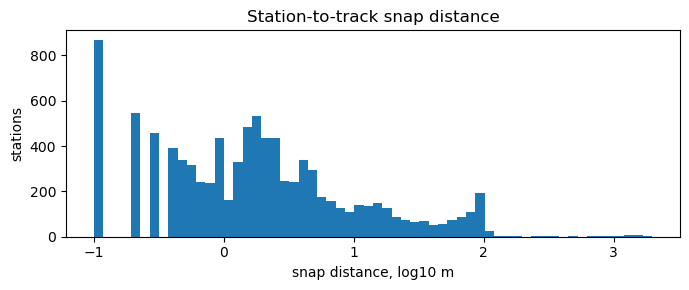

stations without a track within 2 km (snap_too_far), by feed:


feed_key,PL_IC,PL_REG
stations,5,67


stations linking two or more components (gauge breaks, parallel networks):


,feed_key,stop_name,n_components_linked,snap_m
2997,BAHN_AT,Gmünd Bahnhof,2,1.3
2573,BAHN_AT,Gänserndorf Bahnhof,2,1.2
2626,BAHN_AT,Klagenfurt Ostbahnhof,2,5.7
2631,BAHN_AT,Knittelfeld Bahnhof,2,15.4
3045,BAHN_AT,Krakow Plaszow,2,2.1
...,...,...,...,...
529,ZSR_SK,Prievidza,3,0.3
534,ZSR_SK,Pszczyna,2,3.2
594,ZSR_SK,Siebenbrunn-Leopoldsdorf,3,99.6
618,ZSR_SK,Sosnowiec Glowny,3,46.5


In [7]:
tags = pd.read_csv(os.path.join(OUT, 'station_tags.csv'), dtype=str)
snap = R.snap_stations(tags, g, cfg)
n_after_snap, _ = g.components()
cleaning.append({'step': 'station snaps and links', 'nodes': g.n_nodes, 'components': n_after_snap,
                 'added_edges': int(snap['n_components_linked'].sum()),
                 'note': f'nearest track <= {cfg.rail_snap_max_km:g} km (else snap_too_far); every other component '
                         f'within {cfg.rail_station_link_m:g} m linked through the station'})
print(f'components after station links: {n_after_snap:,}')
display(snap['status'].value_counts().to_frame())
ok = snap['snap_m'].dropna()
print('snap distance (m), stations on the network:')
display(ok.describe(percentiles=[.5, .75, .9, .95, .99]).round(1).to_frame().T)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(ok.clip(lower=0.1)), bins=60)
ax.set_xlabel('snap distance, log10 m'); ax.set_ylabel('stations'); ax.set_title('Station-to-track snap distance')
plt.tight_layout(); plt.show()
far = tags[['feed_key', 'stop_name', 'nuts_rg_01_country_id']].join(snap)
print('stations without a track within 2 km (snap_too_far), by feed:')
display(far[far.status == 'snap_too_far'].groupby('feed_key').size().rename('stations').to_frame().T)
print('stations linking two or more components (gauge breaks, parallel networks):')
display(far[far.n_components_linked > 1].sort_values(['feed_key', 'stop_name'])[['feed_key', 'stop_name', 'n_components_linked', 'snap_m']])

## 5b. Bridges over construction track

Some pieces of network that carry served stations are cut off because the OSM dump tags the connecting
stretch `railway=construction` (lines under reconstruction in May 2026 while trains already run on them in
the feed — mostly in Poland). For each such piece, the **shortest path over track + `construction`**
(at most 15 km, `rail_bridge_max_km`) to the main network is found, and **only the edges of that path**
are added (kind `bridge`). Construction track anywhere else — new lines not yet built — is never used,
so it cannot shorten any other distance.

Deliberately **not** bridged: the **Mühlkreisbahn** (Linz Urfahr – Aigen-Schlägl). It has no rail link
across the Danube in reality (the 2 km gap holds only tram, razed and proposed track); its stations stay
`other_component`, with no rail distance.

In [8]:
bridges = R.bridge_components(g, ways, bridge_ways, tags, snap, cfg)
n_after_bridge, _ = g.components()
cleaning.append({'step': 'construction bridges', 'nodes': g.n_nodes, 'components': n_after_bridge,
                 'added_edges': int((g.kind == 'bridge').sum()),
                 'note': f"{int(bridges['bridged'].sum()) if len(bridges) else 0} cut-off pieces joined by the shortest path over "
                         f"track + {cfg.rail_bridge_types} (<= {cfg.rail_bridge_max_km:g} km); that path only"})
display(bridges)

,component_id,stations,n_stations,bridged,bridge_km,construction_km,note
0,110,"Achleitnersiedlung Bahnhst, Aigen-Schlägl Bahn...",19,False,NaN,NaN,no path to the main network within 15 km over ...
1,230,Dygowo,1,True,9.995,9.995,shortest path over track + ['construction']
2,241,Wrzosowo,1,False,NaN,NaN,no path to the main network within 15 km over ...
3,242,"Daszewo, Karlino",2,True,7.070,7.070,shortest path over track + ['construction']
4,253,"Górzyniec, Piechowice, Piechowice Dolne",4,True,14.542,14.542,shortest path over track + ['construction']
5,255,"Jelenia Góra Orle, Jelenia Góra Sobieszów",2,True,11.027,11.027,shortest path over track + ['construction']
6,293,Kudowa-Zdrój,2,False,NaN,NaN,no path to the main network within 15 km over ...
7,303,Duszniki-Zdrój,2,True,10.971,10.971,shortest path over track + ['construction']
8,354,Gołańcz,1,False,NaN,NaN,no path to the main network within 15 km over ...
9,358,Trzebnica,1,False,NaN,NaN,no path to the main network within 15 km over ...


## 6. Distance from Košice and the detour check

**What `rail_km` measures:** the **shortest path along the track infrastructure** between the Košice station
and the station — station → its track → the shortest line on the rails → Košice. It does **not** follow the
route of any train: the timetable is not used, the graph is undirected, and a freight-only line or a connecting
curve without passenger service can be part of the path. It is therefore a lower bound of the distance a
passenger travels. The **route distance** — along the stops a train actually calls at, summed per itinerary
(both legs for one transfer), on this same graph — is computed in notebooks 02 / 03, where the itineraries
exist, and compared with `rail_km` (Reviewer 1: "the geometrically shortest path may not represent the line
actually used by a train").

One Dijkstra from the **Košice station** node (`ZSR_SK` stop 5613600, not the old `hub_latlon`, CF-13) gives
`rail_km` for every station on the hub's component, both station snaps included. `geo_km` is the geodesic
distance; **`detour = rail_km / geo_km` must be ≥ 1** — a value below 1 would be a construction bug.
A station snapped onto a network piece that does not reach Košice is `other_component`.

,count
status,
ok,9350
outside_network,168
snap_too_far,72
other_component,24


detour < 1: 0 (must be 0)


,count,mean,std,min,5%,50%,95%,max
detour,9348.0,1.43,0.185,1.019,1.258,1.384,1.761,3.862


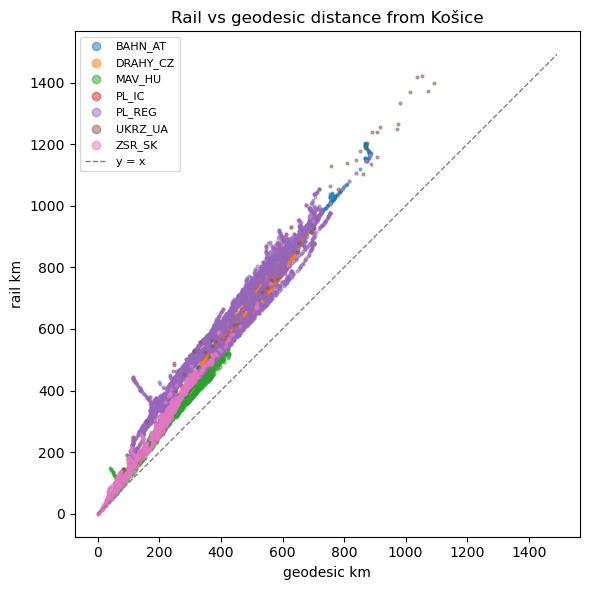

reference check (ŽSR line km: Košice–Žilina 242, Bratislava–Žilina 203):


,feed_key,stop_name,status,snap_m,rail_km,geo_km,detour
844,ZSR_SK,Čierna n.Tisou,ok,0.6,94.68,69.17,1.369
9527,PL_REG,Poprad-Tatry,ok,5.2,100.51,80.60,1.247
2054,UKRZ_UA,Poprad-Tatry,ok,5.5,100.53,80.61,1.247
507,ZSR_SK,Poprad-Tatry,ok,4.5,100.54,80.63,1.247
2963,BAHN_AT,Chop,ok,2.7,103.76,76.33,1.359
89,ZSR_SK,Chop,ok,2.1,103.82,76.34,1.360
868,ZSR_SK,Štrbské Pleso,ok,44.8,123.89,98.65,1.256
2080,UKRZ_UA,Žilina,ok,2.2,241.64,192.87,1.253
884,ZSR_SK,Žilina,ok,31.4,241.73,192.95,1.253
2960,BAHN_AT,Budapest-Keleti,ok,4.5,269.21,211.98,1.270


stations on a component that does not reach Košice (other_component), by feed:


feed_key,BAHN_AT,PL_IC,PL_REG
stations,19,1,4


In [9]:
dist = R.distances_to_hub(tags, snap, g, cfg)
res = tags[['feed_key', 'station_key', 'stop_name', 'nuts_rg_01_country_id']].join(dist)
display(res['status'].value_counts().to_frame())
print(f"detour < 1: {(res['detour'] < 0.999).sum()} (must be 0)")
display(res['detour'].describe(percentiles=[.05, .5, .95]).round(3).to_frame().T)
fig, ax = plt.subplots(figsize=(6, 6))
q = res.dropna(subset=['rail_km', 'geo_km'])
for fk, sub in q.groupby('feed_key'):
    ax.scatter(sub['geo_km'], sub['rail_km'], s=4, alpha=.5, label=fk)
lim = q[['geo_km', 'rail_km']].max().max() * 1.05
ax.plot([0, lim], [0, lim], color='grey', ls='--', lw=1, label='y = x')
ax.set_xlabel('geodesic km'); ax.set_ylabel('rail km'); ax.set_title(f'Rail vs geodesic distance from {cfg.hub_label}')
ax.legend(markerscale=3, fontsize=8); plt.tight_layout(); plt.show()
print('reference check (ŽSR line km: Košice–Žilina 242, Bratislava–Žilina 203):')
chk = ['Žilina', 'Poprad-Tatry', 'Bratislava hl.st.', 'Štrbské Pleso', 'Trenčianske Teplice', 'Čierna n.Tisou',
       'Praha hl.n.', 'Wien Hbf', 'Budapest-Keleti', 'Kraków Główny', 'Chop']
display(res[res.stop_name.isin(chk)].sort_values('rail_km')[['feed_key', 'stop_name', 'status', 'snap_m', 'rail_km', 'geo_km', 'detour']])
print(f'stations on a component that does not reach {cfg.hub_label} (other_component), by feed:')
display(res[res.status == 'other_component'].groupby('feed_key').size().rename('stations').to_frame().T)

## 7. The 31 stations the legacy run could not reach

The legacy network was clipped to Slovakia and kept only `rail` + `narrow_gauge`, so 31 of its 887 domestic
stations had no rail distance: gauge-break islands (Štrba, Trenčianske Teplice), the TEŽ (tagged
`light_rail`), and every foreign station beyond the Slovak clip. Matched by name to the domestic feed.

In [10]:
leg = pd.read_csv('output/ke/station_rail_km.csv', encoding='utf-8-sig').merge(
    pd.read_csv('output/ke/station_catalog.csv', encoding='utf-8-sig', dtype=str)[['station_id', 'name']], on='station_id')
dom = res[res.feed_key == cfg.domestic_feed].drop_duplicates('stop_name')
cmp31 = leg[leg.rail_km.isna()].merge(dom, left_on='name', right_on='stop_name', how='left', suffixes=('_legacy', ''))
display(cmp31[['name', 'rail_snap_km', 'status', 'snap_m', 'n_components_linked', 'rail_km', 'detour']]
        .rename(columns={'rail_snap_km': 'legacy_snap_km'}).sort_values('rail_km'))
far63 = leg[leg.rail_km.notna() & (leg.rail_snap_km > 2)].merge(dom, left_on='name', right_on='stop_name', how='left',
                                                                 suffixes=('_legacy', ''))
print(f'legacy stations WITH a distance but snapped > 2 km: {len(far63)}; now:')
display(far63[['name', 'rail_snap_km', 'rail_km_legacy', 'status', 'snap_m', 'rail_km']]
        .rename(columns={'rail_snap_km': 'legacy_snap_km'}).sort_values('legacy_snap_km'))

,name,legacy_snap_km,status,snap_m,n_components_linked,rail_km,detour
29,Štrba,0.022,ok,21.9,1,119.26,1.232
11,Nová Polianka,6.006,ok,99.6,1,119.89,1.288
17,Tatranský Lieskovec,0.033,ok,32.9,1,120.66,1.241
23,Vyšné Hágy,4.114,ok,86.4,1,122.09,1.288
30,Štrbské Pleso,0.045,ok,44.8,1,123.89,1.256
12,Popradské Pleso,1.070,ok,0.9,1,125.36,1.275
18,Trenčianska Teplá obec,0.085,ok,85.6,1,311.85,1.341
19,Trenčianska Teplá zast.,0.066,ok,65.6,1,313.54,1.356
6,Kaňová,0.092,ok,91.6,1,314.53,1.365
21,Trenčianske Teplice sídl.,0.064,ok,64.2,1,315.26,1.372


legacy stations WITH a distance but snapped > 2 km: 73; now:


,name,legacy_snap_km,rail_km_legacy,status,snap_m,rail_km
52,Tatranská Lesná,2.022,125.33,ok,104.1,114.85
60,Wien Aspern Nord,2.226,479.70,ok,4.6,481.58
56,Veľký Slavkov,3.399,111.98,ok,84.6,105.34
17,Gramatneusiedl,3.455,495.07,ok,48.9,496.89
20,Horný Smokovec,3.544,126.86,ok,90.8,113.26
...,...,...,...,...,...,...
68,Zürich HB,605.661,1090.89,outside_network,NaN,NaN
18,Hamburg Hbf,609.875,1114.22,outside_network,NaN,NaN
19,Hamburg-Altona,613.627,1117.97,outside_network,NaN,NaN
29,Neumünster,649.774,1154.06,outside_network,NaN,NaN


## 8. Outputs

In [11]:
comp = R.components_table(g, dist)
added = R.added_edges_table(g)
clean = pd.DataFrame(cleaning)[['step', 'ways', 'km', 'nodes', 'components', 'added_edges', 'note']]
way_list = ways[['osm_id', 'railway', 'ref', 'name', 'length_km']].copy()
way_list['length_km'] = way_list['length_km'].round(4)
station_out = res[['feed_key', 'station_key', 'stop_name', 'nuts_rg_01_country_id', 'status', 'snap_m',
                   'n_lines_linked', 'n_components_linked', 'node', 'component_id', 'component_km', 'in_hub_component',
                   'rail_km', 'geo_km', 'detour']]
extra = {'OSM extraction date': man['extraction_date'], 'gpkg sha256': man['sha256']}
for name, key, frame in [('station_rail_snap.csv', 'station_rail_snap', station_out),
                         ('rail_network_components.csv', 'rail_network_components', comp),
                         ('rail_network_cleaning.csv', 'rail_network_cleaning', clean),
                         ('rail_network_ways.csv', 'rail_network_ways', way_list),
                         ('rail_network_bridges.csv', 'rail_network_bridges', bridges),
                         ('rail_network_added_edges.csv', 'rail_network_added_edges', added),
                         ('rail_network_length.csv', 'rail_network_length', length)]:
    path = os.path.join(OUT, name)
    frame.to_csv(path, index=False, encoding='utf-8')
    write_meta(path, key, frame, extra)
    print(f'[wrote] {path} ({len(frame):,} rows) + .meta.md')
# The final graph (track, gap joins, station links, bridges), for route distances in 04b: no 8-minute rebuild.
gpath = os.path.join(OUT, 'rail_graph.npz')
g.save(gpath, extra)
print(f'[wrote] {gpath} ({g.n_nodes:,} nodes, {len(g.u):,} edges)')
display(clean)
display(comp.head(10))

[wrote] output\kosice\station_rail_snap.csv (9,614 rows) + .meta.md
[wrote] output\kosice\rail_network_components.csv (1,198 rows) + .meta.md
[wrote] output\kosice\rail_network_cleaning.csv (9 rows) + .meta.md


[wrote] output\kosice\rail_network_ways.csv (297,248 rows) + .meta.md
[wrote] output\kosice\rail_network_bridges.csv (15 rows) + .meta.md


[wrote] output\kosice\rail_network_added_edges.csv (106,313 rows) + .meta.md
[wrote] output\kosice\rail_network_length.csv (7 rows) + .meta.md


[wrote] output\kosice\rail_graph.npz (2,990,134 nodes, 3,243,182 edges)


,step,ways,km,nodes,components,added_edges,note
0,gpkg line features,440511.0,NaN,NaN,NaN,NaN,all railway= values
1,type filter,306582.0,NaN,NaN,NaN,NaN,"railway in ['rail', 'narrow_gauge'] + light_ra..."
2,duplicate osm_id dropped,297250.0,NaN,NaN,NaN,NaN,"9,332 rows repeated a way already present (ove..."
3,identical geometry dropped,297248.0,148650.8,NaN,NaN,NaN,2 further rows with a geometry identical to an...
4,clipped to study area,297248.0,148624.8,NaN,NaN,NaN,"NUTS0 union of ['CZ', 'SK', 'AT', 'HU', 'PL', ..."
5,graph built,NaN,NaN,2882605.0,5820.0,NaN,vertices on a 0.5 m grid; geodesic edge length...
6,gap joins,NaN,NaN,2882605.0,1374.0,8147.0,dead end -> nearest node of another component ...
7,station snaps and links,NaN,NaN,2988353.0,1209.0,9628.0,nearest track <= 2 km (else snap_too_far); eve...
8,construction bridges,NaN,NaN,2990134.0,1198.0,1792.0,10 cut-off pieces joined by the shortest path ...


,component_id,length_km,n_nodes,n_stations,has_hub,centre_lon,centre_lat
0,0,137958.23,2819482,9350,True,19.60691,49.78394
1,966,9110.75,113816,0,False,37.47893,47.46089
2,877,93.64,2856,0,False,28.29527,45.44628
3,110,64.46,3848,19,False,14.06858,48.46555
4,659,57.48,888,0,False,20.65261,53.04965
5,8,52.36,1687,0,False,10.77067,47.47027
6,821,50.17,327,0,False,23.67985,52.75692
7,691,35.08,1123,0,False,20.41547,50.60652
8,468,34.75,889,0,False,19.09747,54.29768
9,779,33.80,825,0,False,22.00372,51.19772
